<a href="https://colab.research.google.com/github/OrastaRakhmatullayeva/PetVision-/blob/main/PetVision_project_ViT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PetVision | Teaching a Model to Recognize Pets

**37 cat and dog breeds · Oxford-IIIT Pet · Vision Transformers**

In this notebook, I try three ways to identify pet breeds from photos: **CLIP zero-shot**, **ViT features + Logistic Regression**, and **ViT fine-tuning**.


**Quick guide:** A *label* is the correct breed; a *feature* is a numerical description of an image; *accuracy* is the share of correct predictions.

### Run this notebook

Use **Google Colab with a GPU** if available. Run the cells from top to bottom; the first run downloads the dataset and pretrained models. Fine-tuning takes longer than the other steps.

In [ ]:
!pip install -q transformers datasets accelerate scikit-learn

In [ ]:
from transformers import AutoImageProcessor , AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

device='cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [ ]:
ds=load_dataset('timm/oxford-iiit-pet')

README.md:   0%|          | 0.00/2.50k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  378MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  413MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3680 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3669 [00:00<?, ? examples/s]

In [ ]:
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'image_id', 'label_cat_dog'],
        num_rows: 3680
    })
    test: Dataset({
        features: ['image', 'label', 'image_id', 'label_cat_dog'],
        num_rows: 3669
    })
})

## 1. Meet the dataset

The Oxford-IIIT Pet dataset contains photos of **37 breeds**. First, let's check how the data is organized and what the labels mean.

In [ ]:
print("Dataset splits:",list(ds.keys()))

print("Train column names:",ds['train'].column_names)

print("Test column names:",ds['test'].column_names)


Dataset splits: ['train', 'test']
Train column names: ['image', 'label', 'image_id', 'label_cat_dog']
Test column names: ['image', 'label', 'image_id', 'label_cat_dog']


### Train, validation, and test

We train on one group of images, check progress on another, and keep the test set aside for the final score. This helps us judge how the model handles photos it hasn't learned from.

In [ ]:
split_ds = ds['train'].train_test_split(test_size=0.1, seed=42)
train = split_ds['train']
val = split_ds['test']

In [ ]:
print('shape of train dataset:',train.shape)

print('shape of val dataset:',val.shape)

print('shape of test dataset:',ds['test'].shape)

shape of train dataset: (3312, 4)
shape of val dataset: (368, 4)
shape of test dataset: (3669, 4)


### What are the breed names?

Each photo has a numeric label. The `names` list translates those numbers into readable breed names.

In [ ]:
ds["train"].features["label"].names

['abyssinian',
 'american_bulldog',
 'american_pit_bull_terrier',
 'basset_hound',
 'beagle',
 'bengal',
 'birman',
 'bombay',
 'boxer',
 'british_shorthair',
 'chihuahua',
 'egyptian_mau',
 'english_cocker_spaniel',
 'english_setter',
 'german_shorthaired',
 'great_pyrenees',
 'havanese',
 'japanese_chin',
 'keeshond',
 'leonberger',
 'maine_coon',
 'miniature_pinscher',
 'newfoundland',
 'persian',
 'pomeranian',
 'pug',
 'ragdoll',
 'russian_blue',
 'saint_bernard',
 'samoyed',
 'scottish_terrier',
 'shiba_inu',
 'siamese',
 'sphynx',
 'staffordshire_bull_terrier',
 'wheaten_terrier',
 'yorkshire_terrier']

In [ ]:
print(train.features['label_cat_dog'])

ClassLabel(names=['cat', 'dog'])


In [ ]:
print(train["label_cat_dog"][:10])

[1, 1, 1, 1, 1, 1, 1, 0, 1, 1]


In [ ]:

category_names = train.features["label_cat_dog"].names

for i, name in enumerate(category_names):
    count = train["label_cat_dog"].count(i)
    print(name, ":", count)


cat : 1072
dog : 2240


### A quick look at the photos

Eight random examples make the task more concrete. The images come in different sizes; later, an image processor will resize them for the model.

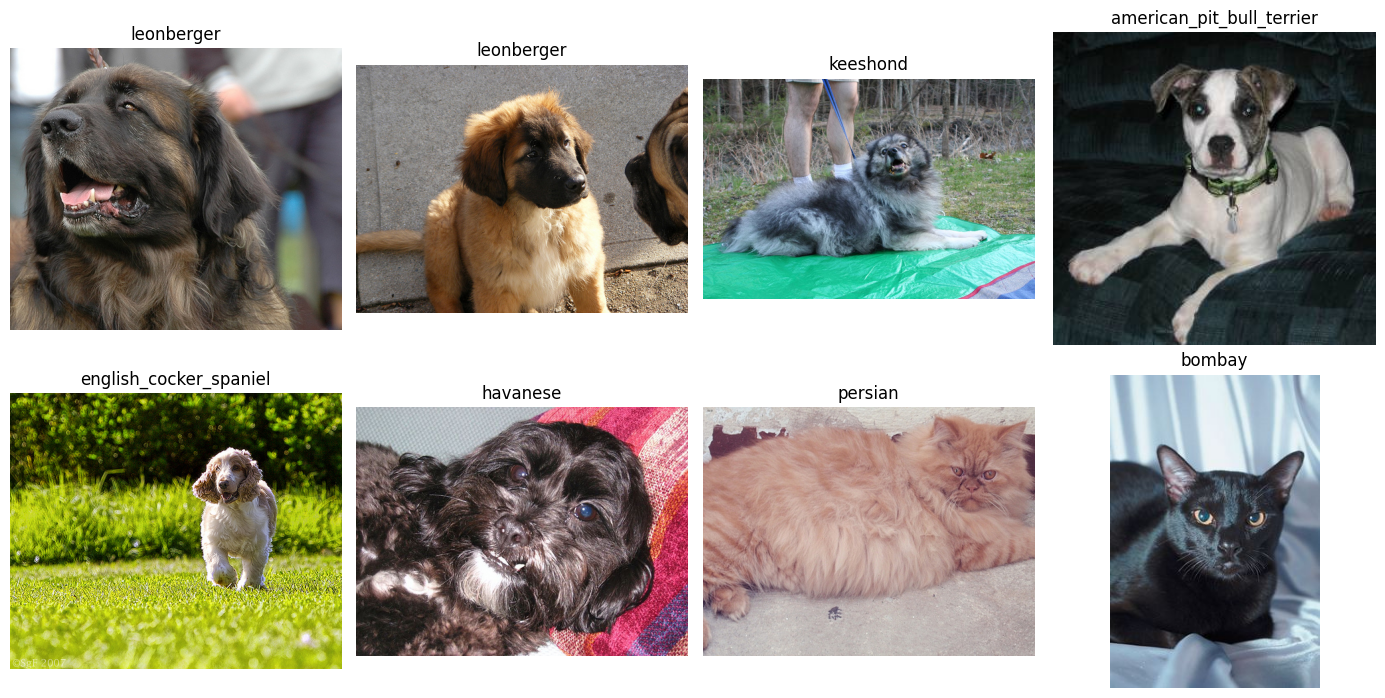

In [ ]:
sample = train.shuffle(seed=42).select(range(8))
names = train.features["label"].names

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    image = sample[i]["image"]
    label = sample[i]["label"]

    ax.imshow(image)
    ax.set_title(names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:

for i in range(5):
    image = train[i]["image"]
    print(f"Image {i + 1}: {image.size}")


Image 1: (500, 375)
Image 2: (300, 225)
Image 3: (332, 500)
Image 4: (300, 252)
Image 5: (290, 300)


### One image up close

Let's inspect a single training photo before passing it to a neural network.

In [ ]:
image = train[0]['image']
print('Image size:', image.size)
display(image)

## 2. How a Vision Transformer sees an image

A **Vision Transformer (ViT)** cuts an image into small square *patches*. It turns each patch into numbers, then learns how the patches relate to one another.

In [ ]:
from transformers import AutoImageProcessor

In [ ]:
model='google/vit-base-patch16-224-in21k'

In [ ]:
processor=AutoImageProcessor.from_pretrained(model)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

In [ ]:
inputs=processor(image.convert('RGB'),
                 return_tensors='pt')

In [ ]:
print(inputs['pixel_values'].shape)

torch.Size([1, 3, 224, 224])


### From patches to image features

At 224 × 224 pixels with 16 × 16 patches, ViT sees **196 patches**. It also uses a special `[CLS]` token, giving **197 tokens** in total. Each token has **768 features** in this model.

The output shape is therefore `[batch, 197, 768]`. These are learned features, **not breed predictions yet**.

In [ ]:
from transformers import AutoModel

In [ ]:
vit = AutoModel.from_pretrained('google/vit-base-patch16-224-in21k')

vit = vit.to(device)   #to generate CPU or GPU
vit.eval()             # evaluation sectionga o'tkazish

with torch.no_grad():
    outputs = vit(
        pixel_values=inputs['pixel_values'].to(device)
    )

hidden = outputs.last_hidden_state   #to print last hidden state from Linear part

print(hidden.shape)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

torch.Size([1, 197, 768])


In [ ]:
device

'cuda'

### Not all vision models use the same patches

Smaller patches mean more tokens. Here we read the settings directly from each model's configuration rather than guessing them.

*Note:* The table counts patches plus a `[CLS]` token. DeiT's distillation architecture can use an additional token.

In [ ]:

from transformers import AutoConfig
import pandas as pd

models = [
    "google/vit-base-patch16-224-in21k",
    "facebook/deit-small-patch16-224",
    "openai/clip-vit-base-patch32"
]

rows = []
# Auto Config is powerful tehnique to get the all configurations of Models
for model_name in models:
    config = AutoConfig.from_pretrained(model_name)

    if "clip" in model_name:
        config = config.vision_config     # CLIP da text part ham bo'lsihi mumkin shuning uchun bu kk

    patch_size = config.patch_size  #to get patch size
    image_size = config.image_size  # to get image size
    hidden_size = config.hidden_size  # to get last hidden size output after Transformer Encoder

    patch_count = (image_size // patch_size) ** 2

    rows.append({
        "Model": model_name,
        "Patch Size": patch_size,
        "Image Size": image_size,
        "Patch Count": patch_count,
        "Tokens (+CLS)": patch_count + 1,
        "Hidden Size": hidden_size
    })

df = pd.DataFrame(rows)
display(df)


,Model,Patch Size,Image Size,Patch Count,Tokens (+CLS),Hidden Size
0,google/vit-base-patch16-224-in21k,16,224,196,197,768
1,facebook/deit-small-patch16-224,16,224,196,197,384
2,openai/clip-vit-base-patch32,32,224,49,50,768


## 3. CLIP: Recognizing breeds without training

CLIP has already learned to connect pictures with text. Instead of training it on our pet photos, we give it 37 short descriptions and ask which one best matches each image. This is called **zero-shot classification**.

### A shared set of 500 test images

We'll reuse these same photos when comparing the methods at the end.

In [ ]:

test_small = ds['test'].shuffle(seed=0).select(range(500))

print("Test images:", len(test_small))


Test images: 500


### Tell CLIP what to look for

A prompt such as *“a photo of a Persian, a type of pet”* gives the model a little context beyond the breed name.

In [ ]:

prompts = []

for name in names:
    clean_name = name.replace("_", " ")
    prompt = f"a photo of a {clean_name}, a type of pet."
    prompts.append(prompt)

print("Number of prompts:", len(prompts))
print(prompts[:5])


Number of prompts: 37
['a photo of a abyssinian, a type of pet.', 'a photo of a american bulldog, a type of pet.', 'a photo of a american pit bull terrier, a type of pet.', 'a photo of a basset hound, a type of pet.', 'a photo of a beagle, a type of pet.']


In [ ]:
from transformers import pipeline

clip_model="openai/clip-vit-base-patch32"

clip=pipeline('zero-shot-image-classification',
              model=clip_model)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

### Try one photo first

Before testing hundreds of images, let's see what CLIP predicts for one.

In [ ]:

image = test_small[0]["image"].convert("RGB")

result = clip(
    image,
    candidate_labels=prompts
)

print("Predicted:", result[0]["label"])
print("Score:", result[0]["score"])
print("Actual:", names[test_small[0]["label"]])

display(image)


### How often is CLIP right?

**Accuracy = correct predictions ÷ total predictions.** Here we measure it across 500 photos.

In [ ]:

imgs = [im.convert("RGB") for im in test_small["image"]]

results = clip(
    imgs,
    candidate_labels=prompts,
    batch_size=32
)

predicted_prompts = [r[0]["label"] for r in results]

prompt_to_id = {
    prompt: i for i, prompt in enumerate(prompts)
}

y_pred = [prompt_to_id[p] for p in predicted_prompts]
y_true = test_small["label"]

from sklearn.metrics import accuracy_score

clip_accuracy = accuracy_score(y_true, y_pred)

print("CLIP Accuracy:", round(clip_accuracy, 4))
print("CLIP Accuracy (%):", round(clip_accuracy * 100, 2))


CLIP Accuracy: 0.838
CLIP Accuracy (%): 83.8


### An easier question: cat or dog?

Identifying the animal type is simpler than identifying its exact breed. Let's see how much the accuracy changes.

In [ ]:

binary_prompts = [
    "a photo of a cat",
    "a photo of a dog"
]

binary_results = clip(
    imgs,
    candidate_labels=binary_prompts,
    batch_size=32
)

binary_predictions = [
    r[0]["label"] for r in binary_results
]

category_names = test_small.features["label_cat_dog"].names

print(category_names)


['cat', 'dog']


In [ ]:

binary_to_id = {}

for i, name in enumerate(category_names):
    if "cat" in name.lower():
        binary_to_id["a photo of a cat"] = i
    elif "dog" in name.lower():
        binary_to_id["a photo of a dog"] = i

print(binary_to_id)


{'a photo of a cat': 0, 'a photo of a dog': 1}


In [ ]:

assert len(binary_to_id) == 2

binary_pred_ids = [
    binary_to_id[label] for label in binary_predictions
]

binary_true = test_small["label_cat_dog"]

binary_accuracy = accuracy_score(
    binary_true,
    binary_pred_ids
)

print("Cat vs Dog Accuracy:", round(binary_accuracy, 4))


Cat vs Dog Accuracy: 0.998


In [ ]:
import pandas as pd

clip_results = pd.DataFrame({
    "Experiment": [
        "37 breeds — template",
        "Cat vs Dog"
    ],
    "Accuracy": [
        clip_accuracy,

        binary_accuracy
    ]
})

display(clip_results)

,Experiment,Accuracy
0,37 breeds — template,0.838
1,Cat vs Dog,0.998


## 4. ViT features + Logistic Regression

What if we use ViT as a **feature extractor** instead? ViT turns each image into a 768-number summary, and a small Logistic Regression classifier learns which breed those numbers describe.

**Only Logistic Regression is trained here.** The pretrained ViT stays unchanged.

In [ ]:
BASE = "google/vit-base-patch16-224-in21k"

proc = AutoImageProcessor.from_pretrained(BASE)
vit = AutoModel.from_pretrained(BASE).to(device).eval()

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

### Turn photos into vectors

We process images in batches so they fit in memory. `h[:, 0]` selects the special `[CLS]` token; `h.mean(dim=1)` averages all tokens.

In [ ]:
@torch.no_grad()
def embed(data, bs=32, pooling="cls"):
    vectors = []

    for i in range(0, len(data), bs):
        images = [im.convert("RGB") for im in data[i:i+bs]["image"]]
        x = proc(images, return_tensors="pt").to(device)
        h = vit(**x).last_hidden_state

        features = h[:, 0] if pooling == "cls" else h.mean(dim=1)
        vectors.append(features.cpu())

    return torch.cat(vectors).numpy()

### Train a small classifier

The image vectors become our inputs (`X`), and the breed labels are the answers (`y`).

In [ ]:
X_train = embed(train)
X_test = embed(ds['test'])

y_train = train["label"]
y_test = ds['test']["label"]

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

logreg_accuracy = accuracy_score(y_test, lr.predict(X_test))
print("CLS Accuracy:", logreg_accuracy)

CLS Accuracy: 0.9209593894794222


### Does averaging the tokens help?

We compare the `[CLS]` vector with **mean pooling** (averaging all token vectors). Both give 768 features, but they may capture the image differently. The test results tell us which works better.

In [ ]:
X_train_mean = embed(train, pooling="mean")
X_test_mean = embed(ds['test'], pooling="mean")

lr_mean = LogisticRegression(max_iter=1000)
lr_mean.fit(X_train_mean, y_train)

mean_accuracy = accuracy_score(y_test, lr_mean.predict(X_test))
print("Mean Accuracy:", mean_accuracy)

Mean Accuracy: 0.919869174161897


## 5. Fine-tune ViT on pet breeds

This time we update the pretrained ViT itself, along with a new 37-breed classification head. Fine-tuning takes more work than feature extraction, but it lets the model adapt to our dataset.

### Add a breed classifier

The pretrained encoder knows useful visual patterns, but its new 37-class prediction layer starts out untrained.

In [ ]:
from transformers import AutoModelForImageClassification

model = AutoModelForImageClassification.from_pretrained(
    BASE,
    num_labels=len(names),
    id2label=dict(enumerate(names)),
    label2id={name: i for i, name in enumerate(names)},
    ignore_mismatched_sizes=True
)

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Prepare images for training

The processor converts each photo to the format ViT expects. We also rename `label` to `labels` so Hugging Face's Trainer can read the answers.

In [ ]:
def transform(batch):

    images = [im.convert("RGB") for im in batch["image"]]
    batch["pixel_values"] = proc(images, return_tensors="pt")["pixel_values"]

    keys_to_remove = ["image", "image_id", "label_cat_dog"]
    for key in keys_to_remove:
        if key in batch:
            del batch[key]

    return batch

train_ds = train.rename_column("label", "labels")
val_ds = val.rename_column("label", "labels")

train_ds.set_transform(transform)
val_ds.set_transform(transform)

### Train for three epochs

An **epoch** is one pass through the training set. The **learning rate** controls the size of weight updates; here we use `2e-4`. After each epoch, we check the validation loss to see whether the model is improving.

In [ ]:
from transformers import TrainingArguments, Trainer

args = TrainingArguments(
    output_dir="pet-vit",
    num_train_epochs=3,
    learning_rate=2e-4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    fp16=(device == "cuda"),
    remove_unused_columns=False,  # Set to False so 'image' column is available in transform()
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds
)

trainer.train()

Epoch,Training Loss,Validation Loss
1,No log,0.861154
2,No log,0.426175
3,0.935445,0.300829


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=621, training_loss=0.7728035046858488, metrics={'train_runtime': 207.2114, 'train_samples_per_second': 47.951, 'train_steps_per_second': 2.997, 'total_flos': 7.70201940716716e+17, 'train_loss': 0.7728035046858488, 'epoch': 3.0})

In [ ]:
# Evaluate the fine-tuned ViT model on the test dataset
test_ds = ds['test'].rename_column("label", "labels")
test_ds.set_transform(transform)

eval_results = trainer.evaluate(test_ds)
print("Fine-tuned ViT Test Metrics:", eval_results)

# perform inference and calculate raw accuracy
predictions = trainer.predict(test_ds)
y_pred_ft = np.argmax(predictions.predictions, axis=1)
y_true_ft = ds['test']["label"]

ft_accuracy = accuracy_score(y_true_ft, y_pred_ft)
print("Fine-tuned ViT Accuracy:", round(ft_accuracy, 4))

Training Loss,Validation Loss,Epoch
0.935445,0.335993,3


Fine-tuned ViT Test Metrics: {'eval_loss': 0.33599260449409485}


Fine-tuned ViT Accuracy: 0.9212


## 6. Where does the model get confused?

An overall accuracy score hides the difficult cases. Let's check **cat vs. dog performance**, the five hardest breeds, the most commonly confused breed pairs, and six mistakes we can inspect ourselves.

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true_ft, y_pred_ft, labels=range(len(names)))

# Breed-level accuracy: correct predictions / examples of that breed
breed_accuracy = cm.diagonal() / cm.sum(axis=1)
print('Five hardest breeds:')
for i in np.argsort(breed_accuracy)[:5]:
    print(f'{names[i]}: {breed_accuracy[i]:.1%}')

# Oxford-IIIT Pet uses capitalized breed names for cats
cat_ids = [i for i, name in enumerate(names) if name[0].isupper()]
cat_mask = np.isin(y_true_ft, cat_ids)
for animal, mask in [('Cats', cat_mask), ('Dogs', ~cat_mask)]:
    print(f'{animal} accuracy: {(y_true_ft[mask] == y_pred_ft[mask]).mean():.1%}')

pairs = sorted(((cm[i, j] + cm[j, i], names[i], names[j])
                for i in range(len(names)) for j in range(i + 1, len(names))), reverse=True)
print('Most confused breed pairs:')
for count, a, b in pairs[:5]:
    print(f'{a} / {b}: {count} mistakes')

In [ ]:
mistakes = np.where(np.array(y_true_ft) != np.array(y_pred_ft))[0][:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, i in zip(axes.flat, mistakes):
    ax.imshow(ds['test'][int(i)]['image'])
    ax.set_title(f'Actual: {names[y_true_ft[i]]}\nPredicted: {names[y_pred_ft[i]]}', fontsize=9)
    ax.axis('off')
for ax in axes.flat[len(mistakes):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

**What might explain these mistakes?** Similar fur, faces, and body shapes can make two breeds hard to tell apart. Camera angles and lighting may also hide useful details. The examples above help us see whether those explanations fit our model's actual errors.

## 7. Put the three approaches side by side

For a fair comparison, all three accuracy scores should use **the same 500 test photos**. Training time is different from inference time: zero-shot CLIP needs no task-specific training, while fine-tuning updates the full ViT model.

In [ ]:
small_ds = test_ds.shuffle(seed=0).select(range(500))
p500 = trainer.predict(small_ds)

vit_accuracy = (
    np.argmax(p500.predictions, axis=1) == p500.label_ids
).mean()

In [ ]:
# Evaluate Logistic Regression on the same shuffled 500 images as CLIP and ViT
X_test_500 = embed(test_small)
logreg_accuracy_500 = accuracy_score(test_small['label'], lr.predict(X_test_500))

In [ ]:
results = pd.DataFrame({
    'Method': ['CLIP Zero-shot', 'ViT + Logistic Regression', 'ViT Fine-tuning'],
    'Accuracy (%)': [round(clip_accuracy * 100, 2),
                     round(logreg_accuracy_500 * 100, 2),
                     round(vit_accuracy * 100, 2)],
    'Training': ['None', 'Classifier only', 'Full ViT + classifier'],
    'Training time': ['0 s', 'Not recorded', '207 s']
})
display(results)

## What I learned

**CLIP zero-shot:** **83.8%** on 500 images, with no pet-specific training. It's a useful starting point when labels or training time are limited.

**ViT + Logistic Regression:** **92.10%** on the *full* 3,669-image test set using `[CLS]` features; mean pooling reached **91.99%** on that same set. A simple classifier can do surprisingly well with good pretrained features.

**Fine-tuned ViT:** **92.12%** on the full test set and **92.6%** on the selected 500 images after three epochs. Its 500-image score is promising; the corrected comparison cell above measures Logistic Regression on those same images before ranking the methods.

### If I had to choose

- **Very little labeled data (say, 20 photos):** I'd start with CLIP zero-shot, then test a small classifier on frozen features.
- **A new animal class, such as hamster:** CLIP is easiest to extend: add a text description and try it without retraining.
- **Enough labeled examples and compute:** Fine-tuning is worth testing, but I'd keep the simpler baseline to see whether the extra work pays off.

**Takeaway:** A bigger training process doesn't automatically mean a much better model. The fair test is how well each approach works on the same unseen images.

*Reproducibility note:* The original train/validation split uses `seed=42` without stratification; the comparison subset uses `seed=0`. Recorded scores come from the original run. New analysis and the corrected comparison table will populate when those cells are run.